# Дополнительное задание. Глубокая кластеризация

Задание выполняю на том же датасете, что и лабораторную работу 3 (Dry Bean Dataset). Из предложенных методов выбрал самоорганизующуюся карту Кохонена (SOM): это нейросетевой метод обучения без учителя, который строит двумерную карту, сохраняющую топологию данных, поэтому результат удобно визуализировать и интерпретировать. Карту реализовал сам на numpy, а для сравнения взял K-means, EM и DBSCAN.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)

sns.set_theme(style="whitegrid")
RS = 42

Подключил библиотеки и зафиксировал random_state для воспроизводимости результатов.

In [2]:
df = pd.read_excel("Dry_Bean_Dataset.xlsx")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

Загрузил данные. В таблице 13611 объектов и 17 столбцов: 16 числовых признаков геометрии зерна и текстовый Class с семью сортами фасоли. Пропусков нет, во всех столбцах по 13611 значений. Категориальных признаков для кодирования нет, Class в обучении не использую, он нужен только для внешних метрик.

In [3]:
dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
dup, df.shape

(np.int64(68), (13543, 17))

Нашёл 68 полностью совпадающих строк и удалил их, осталось 13543 объекта.

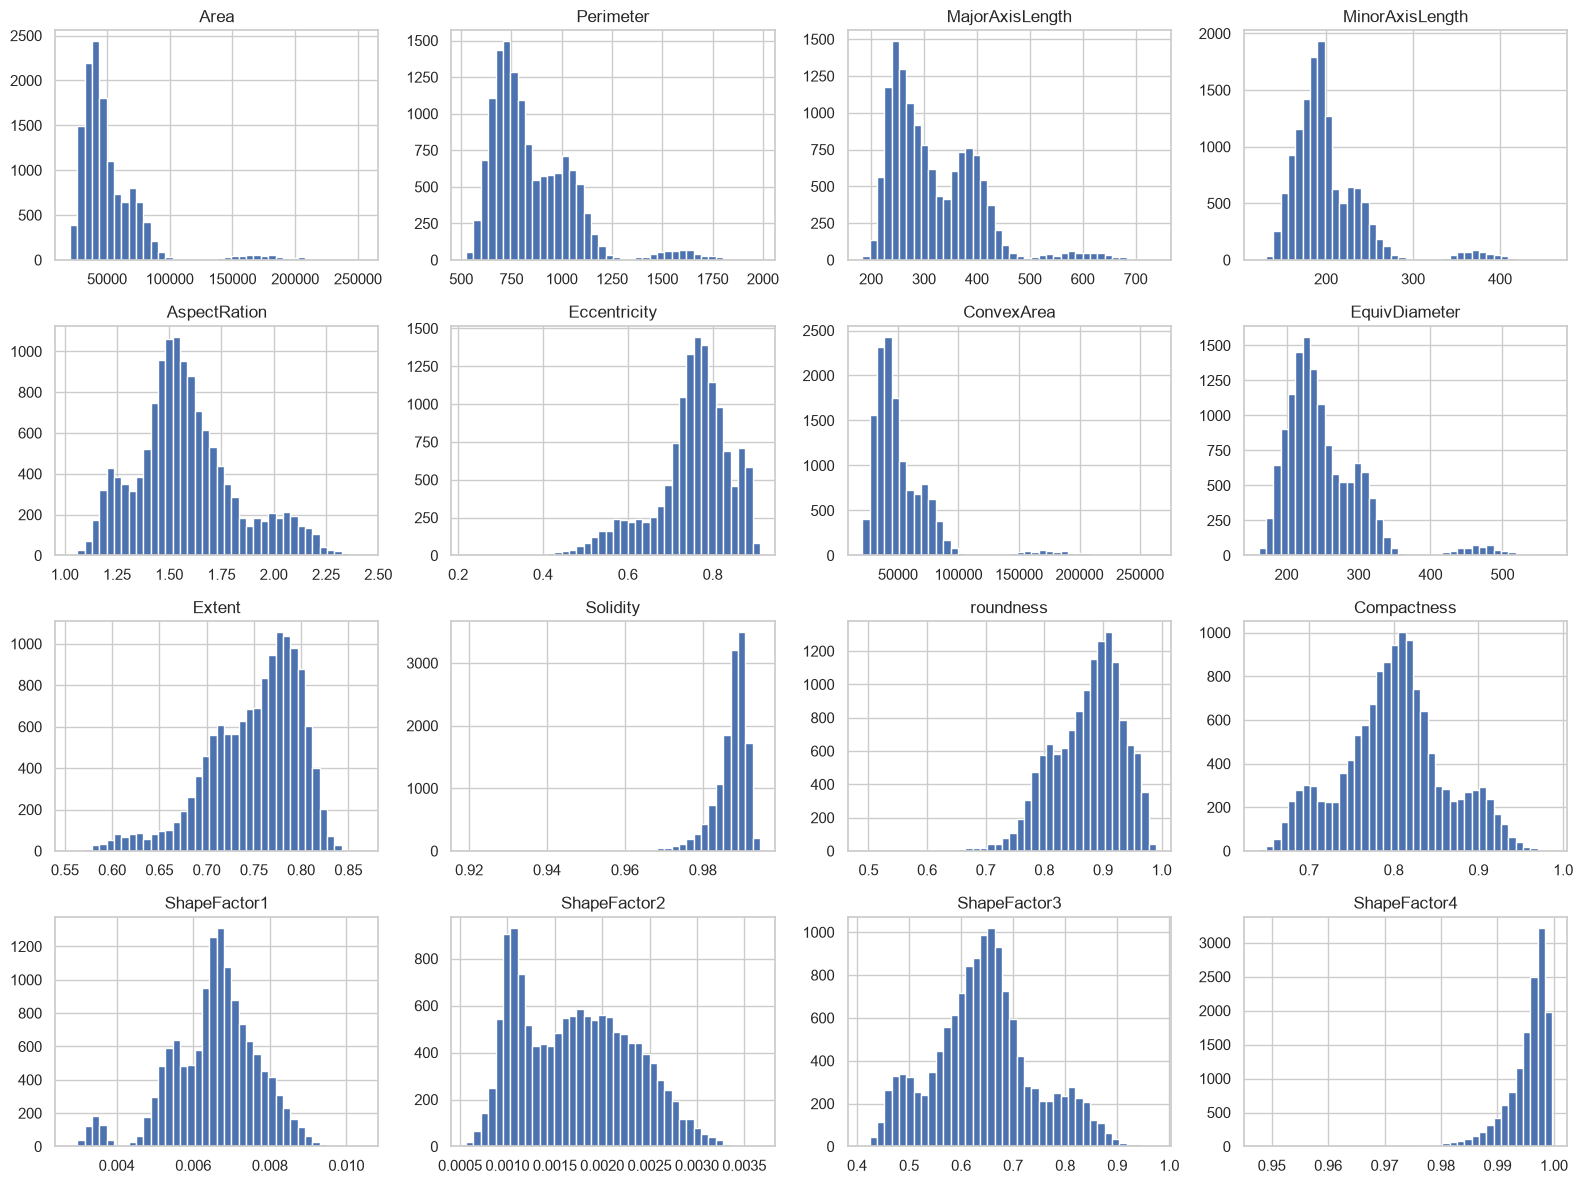

In [4]:
X = df.drop(columns="Class")
y = df["Class"]
X.hist(bins=40, figsize=(16, 12))
plt.tight_layout()
plt.show()

Распределения признаков не нормальные: Area, Perimeter, MinorAxisLength и ConvexArea скошены вправо и имеют отдельный горб в области больших значений (крупные зёрна), Solidity и ShapeFactor4 скошены влево, у AspectRation, ShapeFactor2 и ShapeFactor3 видно несколько вершин. Это говорит о том, что данные состоят из нескольких групп.

In [5]:
corr = X.corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
pairs[pairs > 0.95].sort_values(ascending=False).round(3)

Area             ConvexArea         1.000
Compactness      ShapeFactor3       0.999
Perimeter        EquivDiameter      0.991
AspectRation     Compactness        0.988
ConvexArea       EquivDiameter      0.985
Area             EquivDiameter      0.985
Eccentricity     ShapeFactor3       0.981
AspectRation     ShapeFactor3       0.979
Perimeter        MajorAxisLength    0.978
Eccentricity     Compactness        0.970
Perimeter        ConvexArea         0.968
Area             Perimeter          0.967
MajorAxisLength  EquivDiameter      0.962
Area             MinorAxisLength    0.952
MinorAxisLength  ConvexArea         0.952
dtype: float64

Нашёл 15 пар признаков с корреляцией выше 0,95. Размерные признаки (Area, ConvexArea, EquivDiameter, Perimeter и оси) почти дублируют друг друга, то же самое с признаками формы AspectRation, Eccentricity, Compactness и ShapeFactor3. Для Area и ConvexArea коэффициент равен 1,00, для Compactness и ShapeFactor3 он 0,999.

In [6]:
X = X.drop(columns=["ConvexArea", "EquivDiameter", "Compactness"])
scaler = StandardScaler()
Xs = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
Xs.shape

(13543, 13)

Убрал ConvexArea, EquivDiameter и Compactness, как и в лабораторной работе, осталось 13 признаков. Затем стандартизировал их через StandardScaler. SOM и K-means работают с евклидовыми расстояниями, поэтому признаки должны быть в одной шкале, иначе размерные признаки с большими значениями определяли бы положение узлов карты.

In [7]:
def hopkins(data, m=500, seed=RS):
    rng = np.random.default_rng(seed)
    data = np.asarray(data)
    idx = rng.choice(len(data), m, replace=False)
    uniform = rng.uniform(data.min(axis=0), data.max(axis=0), size=(m, data.shape[1]))
    nn = NearestNeighbors(n_neighbors=2).fit(data)
    w = nn.kneighbors(data[idx], return_distance=True)[0][:, 1]
    u = nn.kneighbors(uniform, return_distance=True)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())

round(hopkins(Xs), 3)

np.float64(0.948)

Статистика Хопкинса равна 0,948, это говорит о выраженной кластерной тенденции. Размерность небольшая (13 признаков), пропусков нет, выбросы по правилу 1,5 IQR в лабораторной работе занимали не больше 6,2 % в каждом признаке, и я их не удалял, так как они относятся к реальной группе крупных зёрен. По лабораторной работе предполагаемое число групп 3-4 (по силуэту и диаграммам), а сортов в данных семь. Данные для кластеризации подходят.

In [8]:
class SOM:
    def __init__(self, rows, cols, lr0=0.5, sigma0=5, seed=RS):
        self.rows, self.cols, self.lr0, self.sigma0, self.seed = rows, cols, lr0, sigma0, seed
        grid = np.array([(i, j) for i in range(rows) for j in range(cols)], dtype=float)
        self.d2 = ((grid[:, None, :] - grid[None, :, :]) ** 2).sum(-1)

    def dist(self, X):
        return (X ** 2).sum(1)[:, None] - 2 * X @ self.W.T + (self.W ** 2).sum(1)[None, :]

    def bmu(self, X):
        return self.dist(X).argmin(1)

    def fit(self, X, epochs=20, batch=32, lr_end=0.01, sigma_end=0.5):
        rng = np.random.default_rng(self.seed)
        n = len(X)
        self.W = X[rng.choice(n, self.rows * self.cols, replace=False)].copy()
        steps, t = epochs * int(np.ceil(n / batch)), 0
        for _ in range(epochs):
            perm = rng.permutation(n)
            for s in range(0, n, batch):
                xb = X[perm[s:s + batch]]
                lr = self.lr0 * (lr_end / self.lr0) ** (t / steps)
                sigma = self.sigma0 * (sigma_end / self.sigma0) ** (t / steps)
                H = np.exp(-self.d2[self.bmu(xb)] / (2 * sigma ** 2))
                self.W += lr * (H.T @ xb - H.sum(0)[:, None] * self.W) / len(xb)
                t += 1
        return self

    def errors(self, X):
        d = self.dist(X)
        first_two = np.argsort(d, axis=1)[:, :2]
        qe = np.sqrt(np.maximum(d[np.arange(len(X)), first_two[:, 0]], 0)).mean()
        te = (self.d2[first_two[:, 0], first_two[:, 1]] > 2).mean()
        return qe, te

Реализовал SOM. Обоснование архитектуры и функции потерь следующее. Сеть однослойная: вход 13 признаков, выход прямоугольная решётка нейронов, у каждого нейрона вектор весов из 13 компонент. Энкодера и декодера здесь нет, роль латентного пространства играет двумерная решётка: объект кодируется координатами нейрона-победителя (BMU), а восстанавливается весами этого нейрона. Размерность латентного пространства 2, чтобы карту можно было анализировать визуально, а размер решётки подберу ниже.

Функция потерь это ошибка квантования с гауссовой функцией соседства, то есть сумма по нейронам h(d) * ||x - w||^2. KL-дивергенции и отдельного clustering loss у SOM нет. Регуляризацией служит радиус соседства sigma: чем он больше, тем сильнее соседние узлы тянутся друг к другу и тем более гладкая карта. Скорость обучения и sigma убывают по экспоненте от начальных значений lr0 и sigma0 до 0,01 и 0,5. Обучение идёт мини-батчами по 32 объекта, 20 эпох, веса инициализируются случайными объектами выборки. Кластеры получаю вторым шагом: K-means по векторам весов узлов (с весами по числу попавших в узел объектов), объект получает кластер своего узла. Качество карты оцениваю ошибкой квантования QE (среднее расстояние до узла-победителя) и топографической ошибкой TE (доля объектов, у которых два ближайших узла не соседние на решётке).

In [9]:
Xv = Xs.values
som = SOM(10, 10, lr0=0.5, sigma0=5).fit(Xv)
pd.Series(dict(zip(["QE", "TE"], som.errors(Xv)))).round(3)

QE    1.058
TE    0.026
dtype: float64

Обучил карту 10x10 с lr0 = 0,5 и sigma0 = 5. Средняя ошибка квантования 1,058 в единицах стандартного отклонения признаков, топографическая ошибка 0,026: у 97,4 % объектов два ближайших узла соседние, то есть карта сохраняет топологию данных.

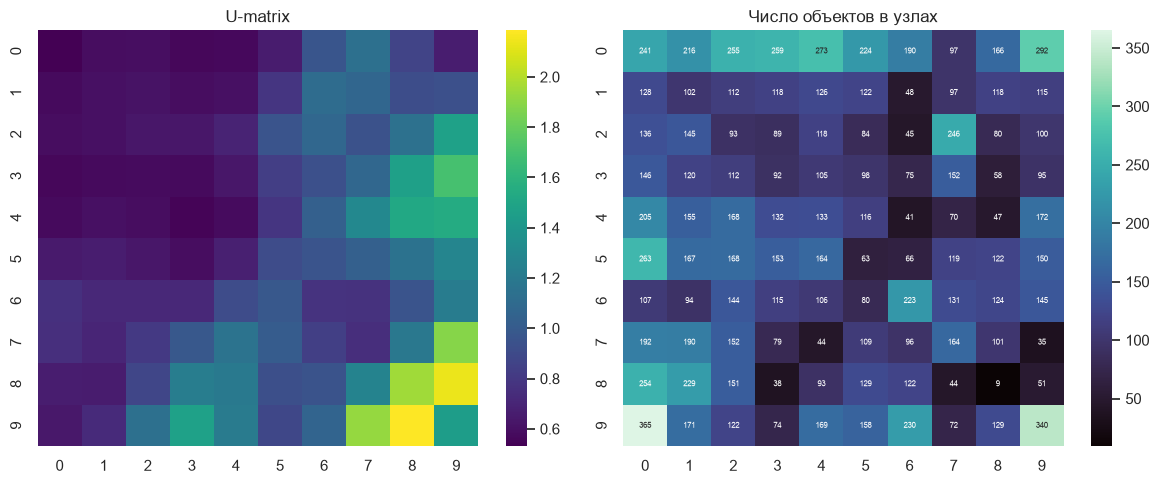

In [10]:
W = som.W.reshape(10, 10, -1)
umatrix = np.zeros((10, 10))
for i in range(10):
    for j in range(10):
        nb = [W[a, b] for a, b in [(i - 1, j), (i + 1, j), (i, j - 1), (i, j + 1)] if 0 <= a < 10 and 0 <= b < 10]
        umatrix[i, j] = np.mean([np.linalg.norm(W[i, j] - v) for v in nb])
hits = np.bincount(som.bmu(Xv), minlength=100).reshape(10, 10)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(umatrix, cmap="viridis", ax=ax[0]).set(title="U-matrix")
sns.heatmap(hits, cmap="mako", annot=True, fmt="d", annot_kws={"size": 6}, ax=ax[1]).set(title="Число объектов в узлах")
plt.tight_layout()
plt.show()

На U-матрице (среднее расстояние между весами соседних узлов) тёмная область занимает левую и верхнюю часть карты: там соседние узлы близки, это плотная основная масса зёрен. Светлая область в правом нижнем углу означает большие расстояния между соседними узлами, то есть границу с редкой группой крупных зёрен. Карта попаданий показывает неравномерное заполнение: в большинстве узлов от 90 до 270 объектов, а в узлах на границе групп их мало (например, 9, 35 и 44).

In [11]:
rows = []
for size in [5, 8, 10, 15, 20]:
    qe, te = SOM(size, size, lr0=0.5, sigma0=size / 2).fit(Xv).errors(Xv)
    rows.append({"размер карты": f"{size}x{size}", "узлов": size * size, "QE": qe, "TE": te})
pd.DataFrame(rows).set_index("размер карты").round(3)

,узлов,QE,TE
размер карты,,,
5x5,25,1.338,0.029
8x8,64,1.121,0.029
10x10,100,1.058,0.026
15x15,225,0.969,0.024
20x20,400,0.921,0.020


Исследовал влияние размера карты. Ошибка квантования монотонно уменьшается с ростом карты (1,338 для 5x5 и 0,921 для 20x20), топографическая ошибка почти не меняется (0,02-0,03). Выигрыш затухает: переход от 10x10 к 15x15 снижает QE примерно на 0,09 ценой 125 дополнительных узлов, а на карте 20x20 в среднем только около 34 объектов на узел. Выбрал 10x10: в среднем около 135 объектов на узел, и карту ещё удобно разбирать глазами.

In [12]:
res = {}
for lr in [0.05, 0.1, 0.5, 1.0]:
    for sg in [0.5, 1, 2, 3, 5, 7]:
        res[(lr, sg)] = SOM(10, 10, lr0=lr, sigma0=sg).fit(Xv).errors(Xv)
grid = pd.DataFrame(res, index=["QE", "TE"]).T
grid.index.names = ["lr", "sigma"]
pd.concat({"QE": grid["QE"].unstack(), "TE": grid["TE"].unstack()}, axis=1).round(3)

QE                                        TE                       \
sigma    0.5    1.0    2.0    3.0    5.0    7.0    0.5    1.0    2.0    3.0   
lr                                                                            
0.05   1.047  1.020  1.045  1.064  1.109  1.110  0.725  0.197  0.061  0.042   
0.10   1.015  1.005  1.045  1.066  1.078  1.105  0.549  0.166  0.078  0.029   
0.50   0.970  0.986  1.013  1.036  1.058  1.072  0.354  0.108  0.068  0.052   
1.00   0.955  0.973  1.008  1.027  1.051  1.065  0.271  0.104  0.063  0.032   

                     
sigma    5.0    7.0  
lr                   
0.05   0.039  0.023  
0.10   0.025  0.034  
0.50   0.026  0.025  
1.00   0.027  0.025

Исследовал влияние скорости обучения и радиуса соседства (регуляризации). Sigma влияет сильнее, чем lr. При малых sigma (0,5 и 1) ошибка квантования ниже (0,955-1,05), но топографическая ошибка вырастает до 0,10-0,73: карта теряет упорядоченность, и узлы работают почти как независимые центры K-means. При sigma = 5-7 топографическая ошибка около 0,025-0,039, но QE выше (1,05-1,11), потому что сильное сглаживание тянет узлы друг к другу. Скорость обучения при lr0 от 0,5 до 1 почти ничего не меняет, а при 0,05 карта хуже упорядочивается (TE 0,725 при sigma = 0,5). Оставил lr0 = 0,5 и sigma0 = 5: это одно из лучших сочетаний низкой топографической ошибки (0,026) и умеренной ошибки квантования (1,058).

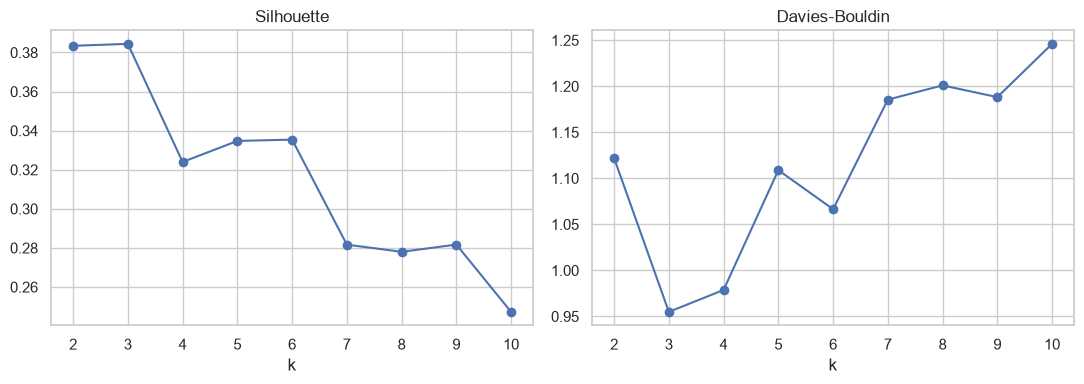

,Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,
2,0.383,1.122,8729.871
3,0.384,0.955,7566.423
4,0.324,0.979,7100.588
5,0.335,1.109,7105.902
6,0.335,1.066,6770.663
7,0.282,1.185,6527.622
8,0.278,1.201,6160.853
9,0.282,1.188,5964.469
10,0.247,1.246,5605.285


In [13]:
def cluster_map(som, k, X):
    hits = np.bincount(som.bmu(X), minlength=len(som.W))
    return KMeans(n_clusters=k, n_init=10, random_state=RS).fit(som.W, sample_weight=hits).labels_

ks = range(2, 11)
rows = []
for k in ks:
    lab = cluster_map(som, k, Xv)[som.bmu(Xv)]
    rows.append({"k": k, "Silhouette": silhouette_score(Xv, lab),
                 "Davies-Bouldin": davies_bouldin_score(Xv, lab),
                 "Calinski-Harabasz": calinski_harabasz_score(Xv, lab)})
sel = pd.DataFrame(rows).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(sel.index, sel["Silhouette"], "o-")
ax[0].set(xlabel="k", title="Silhouette")
ax[1].plot(sel.index, sel["Davies-Bouldin"], "o-")
ax[1].set(xlabel="k", title="Davies-Bouldin")
plt.tight_layout()
plt.show()
sel.round(3)

Подобрал число кластеров для K-means по узлам карты. Силуэт максимален при k = 3 (0,384), при k = 2 почти так же (0,383), дальше снижается до 0,247 при k = 10. Индекс Дэвиса-Болдина минимален при k = 3 (0,955). Индекс Калински-Харабаза только убывает, от 8730 при k = 2, и для выбора не годится. Итого взял k = 3, как и в лабораторной работе 3.

In [14]:
rows = []
for eps in [0.4, 0.5, 0.6, 0.7, 0.8, 1.0, 1.2, 1.5]:
    lab = DBSCAN(eps=eps, min_samples=26).fit_predict(Xv)
    rows.append({"eps": eps, "кластеров": len(set(lab) - {-1}), "шум, %": (lab == -1).mean() * 100})
pd.DataFrame(rows).set_index("eps").round(1)

,кластеров,"шум, %"
eps,,
0.4,4,90.8
0.5,1,64.0
0.6,4,50.1
0.7,6,36.7
0.8,2,24.2
1.0,2,9.7
1.2,2,5.0
1.5,2,2.3


Для DBSCAN взял min_samples = 26 (удвоенное число признаков) и перебрал eps. При eps до 0,8 шумом оказывается от четверти до 90 % объектов, а число кластеров прыгает (4, 1, 4, 6, 2). С eps = 1,0 шум составляет 9,7 %, а при дальнейшем росте eps число кластеров не меняется и остаётся равным 2. Взял eps = 1,0.

In [15]:
K = 3
lab_som = cluster_map(som, K, Xv)[som.bmu(Xv)]
lab_km = KMeans(K, n_init=10, random_state=RS).fit_predict(Xv)
lab_gm = GaussianMixture(K, covariance_type="full", n_init=3, random_state=RS).fit(Xv).predict(Xv)
lab_db = DBSCAN(eps=1.0, min_samples=26).fit_predict(Xv)
lab_som7 = cluster_map(som, 7, Xv)[som.bmu(Xv)]
lab_km7 = KMeans(7, n_init=10, random_state=RS).fit_predict(Xv)

pd.Series(lab_db).value_counts().rename("объектов")

 0    11994
-1     1319
 1      230
Name: объектов, dtype: int64

Получил разбиения: SOM + K-means, K-means и EM с k = 3, DBSCAN, а также K-means и SOM + K-means с k = 7 для сопоставления с числом сортов. DBSCAN выделил один большой кластер из 11994 объектов, маленький из 230 и 1319 шумовых точек (9,7 %). Зёрна образуют непрерывное облако без разрывов по плотности, поэтому DBSCAN сливает почти всё в один кластер.

In [16]:
def quality(labels):
    m = labels != -1
    Xm, ym, lm = Xv[m], y[m], labels[m]
    return {
        "Silhouette": silhouette_score(Xm, lm),
        "Davies-Bouldin": davies_bouldin_score(Xm, lm),
        "Calinski-Harabasz": calinski_harabasz_score(Xm, lm),
        "ARI": adjusted_rand_score(ym, lm),
        "NMI": normalized_mutual_info_score(ym, lm),
        "Homogeneity": homogeneity_score(ym, lm),
        "Completeness": completeness_score(ym, lm),
    }

models = {"K-means (k=3)": lab_km, "EM (k=3)": lab_gm, "DBSCAN": lab_db,
          "SOM + K-means (k=3)": lab_som, "K-means (k=7)": lab_km7, "SOM + K-means (k=7)": lab_som7}
pd.DataFrame({name: quality(lab) for name, lab in models.items()}).T.round(3)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI,Homogeneity,Completeness
K-means (k=3),0.391,0.950,7630.494,0.296,0.483,0.349,0.782
EM (k=3),0.329,1.418,6285.799,0.325,0.474,0.361,0.688
DBSCAN,0.535,0.509,1662.793,0.017,0.100,0.053,1.000
SOM + K-means (k=3),0.384,0.955,7566.423,0.290,0.471,0.342,0.761
K-means (k=7),0.293,1.143,6768.979,0.661,0.706,0.698,0.714
SOM + K-means (k=7),0.282,1.185,6527.622,0.654,0.695,0.690,0.699


Сравнил методы по внутренним и внешним метрикам. SOM + K-means при k = 3 почти повторяет обычный K-means: силуэт 0,384 против 0,391, Дэвис-Болдин 0,955 против 0,950, ARI 0,290 против 0,296, то есть выигрыша по метрикам нейросетевой метод не дал. EM лучше по ARI (0,325) и однородности (0,361), но хуже по внутренним метрикам (силуэт 0,329, Дэвис-Болдин 1,418). У DBSCAN самые высокие внутренние значения (силуэт 0,535, Дэвис-Болдин 0,509), но метрики посчитаны без шума и по двум кластерам, один из которых содержит почти все объекты, поэтому ARI всего 0,017, а полнота 1,0 получилась тривиально. При k = 7 оба метода намного лучше совпадают с сортами (ARI 0,661 у K-means и 0,654 у SOM, NMI 0,706 и 0,695, однородность и полнота около 0,7), при этом внутренние метрики хуже (силуэт 0,293 и 0,282).

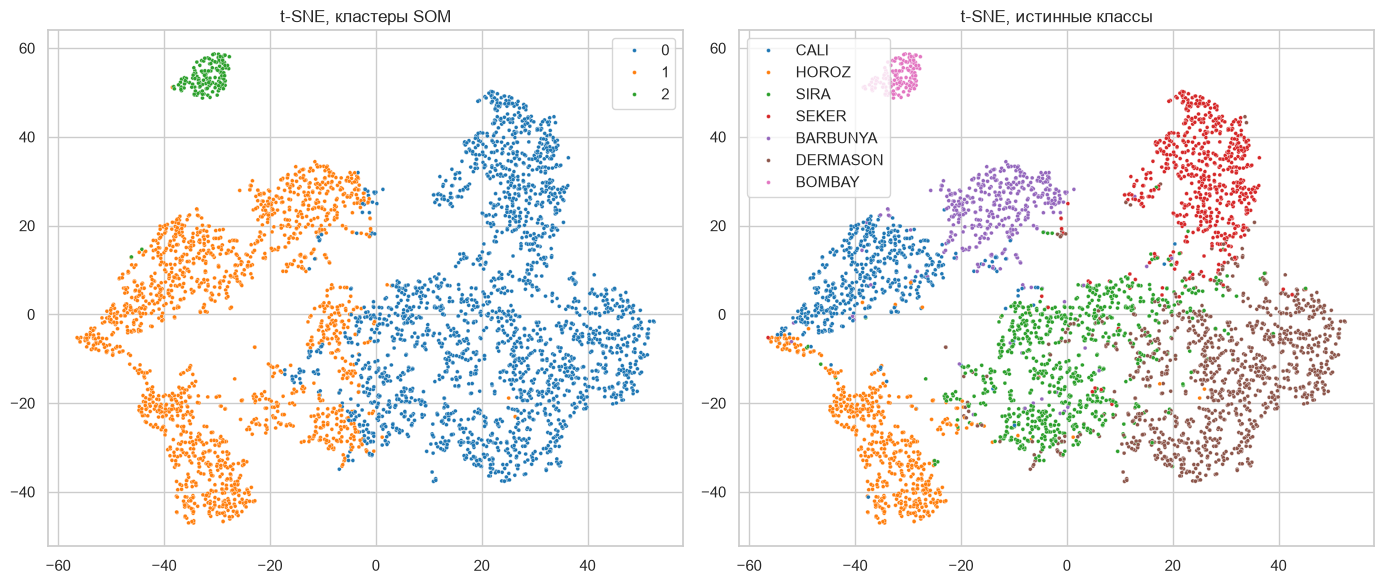

In [17]:
rng = np.random.default_rng(RS)
idx = rng.choice(len(Xv), 4000, replace=False)
emb = TSNE(n_components=2, perplexity=40, random_state=RS).fit_transform(Xv[idx])

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=lab_som[idx], palette="tab10", s=8, ax=ax[0]).set(title="t-SNE, кластеры SOM")
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y.values[idx], palette="tab10", s=8, ax=ax[1]).set(title="t-SNE, истинные классы")
plt.tight_layout()
plt.show()

Визуализировал данные через t-SNE на случайной выборке из 4000 объектов. Структура на нём видна лучше, чем на PCA в лабораторной работе: Bombay образует изолированный остров, отдельными скоплениями лежат Cali, Horoz, Barbunya, Seker и Dermason, а Sira расположена в центре и частично перекрывается с Dermason, Horoz и Cali. Кластеры SOM при k = 3 объединяют эти скопления в три крупные группы: левая часть (Cali, Horoz, Barbunya) это кластер 1, правая (Seker, Dermason, Sira) это кластер 0, остров Bombay это кластер 2. Этим объясняется, почему внутренние метрики выбирают k = 3: на уровне крупных групп разделение хорошее, а внутри них границы размыты.

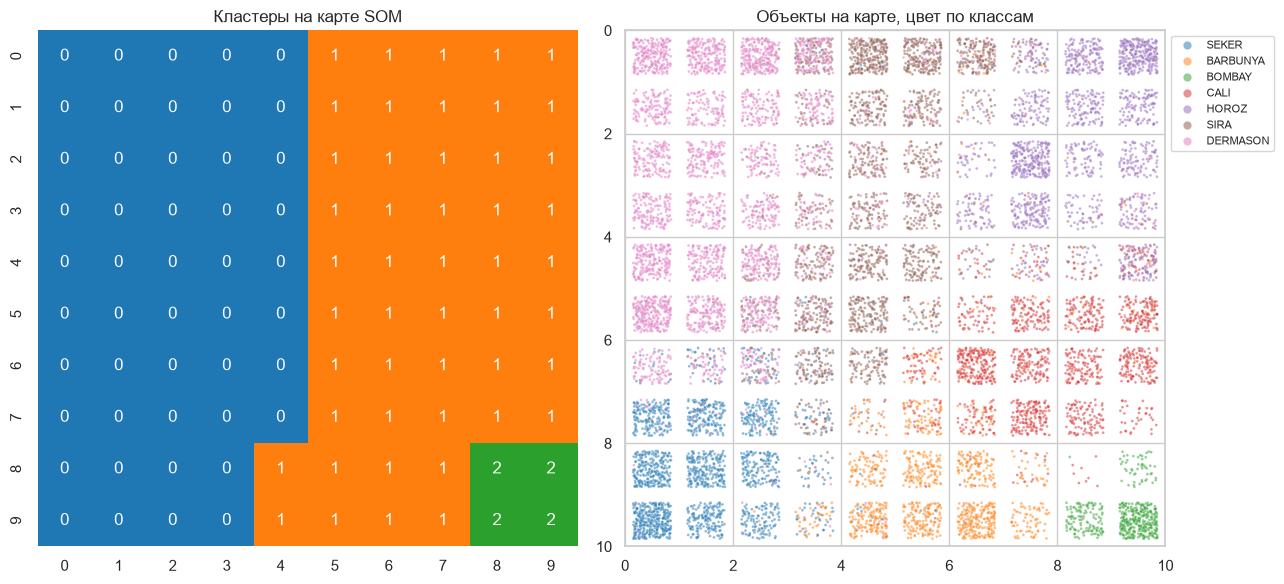

In [18]:
neuron_lab = cluster_map(som, K, Xv)
bmu = som.bmu(Xv)
pos = np.column_stack([bmu // 10, bmu % 10]) + rng.uniform(-0.35, 0.35, size=(len(Xv), 2))

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
sns.heatmap(neuron_lab.reshape(10, 10), cmap="tab10", vmin=0, vmax=9, annot=True, cbar=False, ax=ax[0]).set(title="Кластеры на карте SOM")
sns.scatterplot(x=pos[:, 1] + 0.5, y=pos[:, 0] + 0.5, hue=y.values, palette="tab10", s=4, alpha=0.5, ax=ax[1])
ax[1].set(xlim=(0, 10), ylim=(10, 0), title="Объекты на карте, цвет по классам")
ax[1].legend(markerscale=3, fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Карта SOM показывает, что семь сортов занимают на ней отдельные области: Dermason в левом верхнем углу, Sira в верхней середине, Seker в левом нижнем углу, Horoz в правом верхнем углу, Cali правее центра, Barbunya внизу в центре, Bombay в правом нижнем углу. Кластеры при k = 3 это левая часть карты, правая часть и угловой блок 2x2, то есть разбиение грубее, чем структура, которую запомнила сама карта. Соседние по размеру и форме сорта (Dermason и Sira, Cali и Horoz) лежат рядом, и граница между ними размыта.

In [19]:
profile = X.groupby(lab_som).mean()
profile.insert(0, "size", np.bincount(lab_som))
profile.round(3).T

,0,1,2
size,7321.000,5693.000,529.000
Area,37187.388,62341.217,172547.977
Perimeter,711.427,972.169,1580.835
MajorAxisLength,258.752,373.277,591.601
MinorAxisLength,182.355,212.237,373.055
AspectRation,1.427,1.778,1.587
Eccentricity,0.697,0.817,0.771
Extent,0.760,0.734,0.776
Solidity,0.989,0.985,0.987
roundness,0.916,0.820,0.864


Профили кластеров SOM в исходных единицах. Кластер 0 (7321 объект) мелкие округлые зёрна: площадь около 37 тысяч, главная ось около 259, AspectRation 1,43, roundness 0,916. Кластер 1 (5693 объекта) зёрна среднего размера и более вытянутые: площадь около 62 тысяч, главная ось около 373, AspectRation 1,78, roundness 0,820. Кластер 2 (529 объектов) очень крупные зёрна: площадь около 173 тысяч, главная ось около 592, минимальная ось 373.

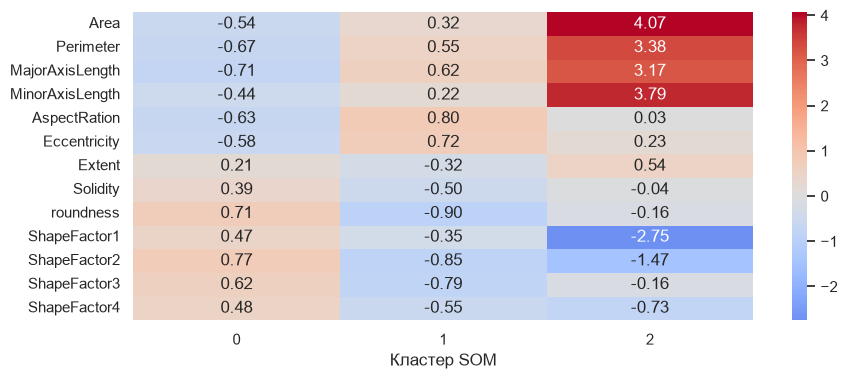

In [20]:
plt.figure(figsize=(10, 4))
sns.heatmap(Xs.groupby(lab_som).mean().T, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.xlabel("Кластер SOM")
plt.show()

По стандартизованным средним видно, какие признаки характерны для каждого кластера. Кластер 0 ниже среднего по всем размерам (от -0,44 до -0,71) и выше по округлости и формфакторам (roundness +0,71, ShapeFactor2 +0,77, ShapeFactor3 +0,62). Кластер 1 немного выше среднего по размерам и сильнее всего выделяется вытянутостью (AspectRation +0,80, Eccentricity +0,72) и низкими roundness (-0,90), ShapeFactor2 (-0,85) и ShapeFactor3 (-0,79). Кластер 2 отличается размерами: Area на 4,07 стандартного отклонения выше среднего, MinorAxisLength на 3,79, Perimeter на 3,38, а ShapeFactor1 ниже среднего на 2,75.

In [21]:
pd.crosstab(y, lab_som)

col_0,0,1,2
Class,,,
BARBUNYA,76,1246,0
BOMBAY,0,1,521
CALI,12,1610,8
DERMASON,3464,82,0
HOROZ,12,1848,0
SEKER,2009,18,0
SIRA,1748,888,0


Кластер 2 практически целиком состоит из Bombay (521 из 529 объектов). Кластер 0 это Dermason (3464), Seker (2009) и большая часть Sira (1748). Кластер 1 это Barbunya (1246), Cali (1610), Horoz (1848) и часть Sira (888). Для этих групп карта работает как грубое разбиение по размеру и форме, а внутри групп сорта не различаются.

In [22]:
base = {"SOM + K-means": lab_som, "K-means": lab_km}
stab = {name: [] for name in base}
for r in range(10):
    sub = np.random.default_rng(r).choice(len(Xv), int(0.8 * len(Xv)), replace=False)
    s = SOM(10, 10, lr0=0.5, sigma0=5, seed=r).fit(Xv[sub])
    stab["SOM + K-means"].append(adjusted_rand_score(lab_som, cluster_map(s, K, Xv[sub])[s.bmu(Xv)]))
    k_sub = KMeans(K, n_init=10, random_state=r).fit(Xv[sub])
    stab["K-means"].append(adjusted_rand_score(lab_km, k_sub.predict(Xv)))
pd.DataFrame(stab).agg(["mean", "std", "min"]).round(3)

,SOM + K-means,K-means
mean,0.987,0.997
std,0.003,0.002
min,0.982,0.994


Проверил устойчивость: десять раз обучал карту заново на случайных 80 % выборки (с другой инициализацией) и сравнивал метки на всех данных с исходным разбиением. У SOM + K-means средний ARI 0,987, стандартное отклонение 0,003, минимум 0,982. У обычного K-means средний ARI 0,997, стандартное отклонение 0,002, минимум 0,994. Оба разбиения очень устойчивы, но K-means немного стабильнее, так как у карты есть дополнительный источник случайности в виде инициализации и порядка объектов.

Вывод. Я выполнил глубокую кластеризацию Dry Bean Dataset самоорганизующейся картой Кохонена 10x10 (QE 1,058, TE 0,026) и по узлам карты выделил три кластера: мелкие округлые, средние вытянутые и очень крупные зёрна (Bombay). Параметры подбирал по ошибкам карты и по внутренним метрикам: sigma = 5 даёт упорядоченную карту, а lr0 влияет слабо. Число кластеров по силуэту и индексу Дэвиса-Болдина получилось равным 3.

В сравнении с классическими методами SOM + K-means дал почти те же значения метрик, что и обычный K-means (силуэт 0,384 против 0,391, ARI 0,290 против 0,296) и оказался чуть менее устойчивым (средний ARI на подвыборках 0,987 против 0,997). EM лучше совпал с сортами по ARI, но хуже по внутренним метрикам, а DBSCAN слил почти все объекты в один кластер и для этих данных не подходит.

Применение глубокой кластеризации для этого датасета я считаю малооправданным, если нужен только результат разбиения: признаков всего 13, структура в основном описывается обычными методами, а выигрыша по метрикам нет. Польза SOM в другом: карта и t-SNE показали, что сорта фасоли образуют семь отдельных областей, соседние по форме сорта лежат рядом, а три кластера являются лишь грубым уровнем этой структуры. Чтобы сильнее приблизиться к сортам, нужно брать 7 кластеров (ARI 0,654 у SOM и 0,661 у K-means), но тогда внутренние метрики ухудшаются, потому что границы между Dermason, Sira, Cali и Horoz размыты.